# From RNN to LSTM to Transformer

---

Creator: Chung-En Johnny Yu

Content updated: 2026-10-29

Hands-on practice this notebook on your Google Colab:
1. [Click here to open this notebook](https://colab.research.google.com/github/chungenyu6/ai-learning-notebooks/blob/main/02-LLM/live/00_rnn_lstm_to_transformer.ipynb)
2. Now, run the code and practice it!

Extends `02_attention.ipynb` by covering the part that comes *before* attention: recurrent networks, why they struggle, and what the Transformer changed.

**Sources** — sections taken from Raschka are tagged; everything else is written for this notebook:

| Tag | Source |
|---|---|
| 📘 **[MLPyTorch Ch15]** | Raschka, Liu & Mirjalili, *Machine Learning with PyTorch and Scikit-Learn* (Packt, 2022), Ch. 15 — [code & figures](https://github.com/rasbt/machine-learning-book/tree/main/ch15) |
| 📗 **[LLMs-from-scratch Ch3]** | Sebastian Raschka, *Build a Large Language Model (From Scratch)* (Manning, 2024), Ch. 3 — [notebook](https://github.com/rasbt/LLMs-from-scratch/blob/main/ch03/01_main-chapter-code/ch03.ipynb) |

Runs in Google Colab on CPU in a few minutes (faster with a GPU runtime). No model weights are downloaded.

| Part | Content |
|---|---|
| 1 | Sequential data and what an RNN is |
| 2 | Computing RNN activations by hand (checked against `nn.RNN`) |
| 3 | Why long-range dependencies are hard: vanishing gradients |
| 4 | The LSTM cell |
| 5 | Project: a character-level LSTM language model |
| 6 | From RNNs to attention to the Transformer |
| 7 | Experiment: RNN vs LSTM vs Transformer on long-range recall |
| 8 | Roadmap and interview-style check questions |

---

In [1]:
import math, os, time, urllib.request
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| device:", device)

torch 2.13.0 | device: cpu


## 1. Sequential data and recurrent networks

📘 *[MLPyTorch Ch15] figures*

In sequential data **order matters**: text, speech, sensor streams, DNA. A model has to process the elements in context, not as independent samples. Depending on the task, inputs and outputs can both be sequences:

<img src="https://github.com/chungenyu6/ai-learning-notebooks/blob/main/02-LLM/live/00-rnn_lstm_to_transformer/img/15_02.png?raw=true" width="500px">

*Figure: categories of sequence modeling. Source: MLPyTorch Ch15, Fig. 15.2.*

- **many-to-one**: sentiment of a review; **one-to-many**: image captioning
- **many-to-many (synchronized)**: tagging every frame/word; **many-to-many (delayed)**: translation — and **language modeling** (predict the next token at every step)

A **recurrent neural network** adds a loop: the hidden layer at step $t$ receives the current input *and* its own previous state.

<img src="https://github.com/chungenyu6/ai-learning-notebooks/blob/main/02-LLM/live/00-rnn_lstm_to_transformer/img/15_03.png?raw=true" width="450px">

*Figure: feedforward network vs. RNN with a recurrent edge. Source: MLPyTorch Ch15, Fig. 15.3.*

"Unfolding" the loop over time shows that the same weights are reused at every step, and that layers can be stacked:

<img src="https://github.com/chungenyu6/ai-learning-notebooks/blob/main/02-LLM/live/00-rnn_lstm_to_transformer/img/15_04.png?raw=true" width="550px">

*Figure: single-layer and multilayer RNNs, folded and unfolded. Source: MLPyTorch Ch15, Fig. 15.4.*

## 2. Computing the activations of an RNN

📘 *[MLPyTorch Ch15] figures and code*

<img src="https://github.com/chungenyu6/ai-learning-notebooks/blob/main/02-LLM/live/00-rnn_lstm_to_transformer/img/15_05.png?raw=true" width="500px">

*Figure: the three weight matrices $W_{xh}$, $W_{hh}$, $W_{ho}$, shared across time. Source: MLPyTorch Ch15, Fig. 15.5.*

$$
h^{(t)}=\tanh\!\big(W_{xh}x^{(t)}+W_{hh}h^{(t-1)}+b_h\big),\qquad o^{(t)}=\sigma_o\!\big(W_{ho}h^{(t)}+b_o\big).
$$

The two formulations below are the same computation — concatenating $[x^{(t)};h^{(t-1)}]$ and using one stacked matrix $W_h=[W_{xh};W_{hh}]$ is how many libraries implement it:

<img src="https://github.com/chungenyu6/ai-learning-notebooks/blob/main/02-LLM/live/00-rnn_lstm_to_transformer/img/15_06.png?raw=true" width="650px">

*Figure: two equivalent formulations of the hidden-state update. Source: MLPyTorch Ch15, Fig. 15.6.*

The code below (from the book) builds a tiny `nn.RNN` and recomputes its output **by hand**, step by step. Note that the update is **sequential**: step $t$ needs step $t-1$.

In [2]:
# Source: MLPyTorch Ch15, ch15_part1.ipynb
torch.manual_seed(1)

rnn_layer = nn.RNN(input_size=5, hidden_size=2, num_layers=1, batch_first=True)

w_xh = rnn_layer.weight_ih_l0
w_hh = rnn_layer.weight_hh_l0
b_xh = rnn_layer.bias_ih_l0
b_hh = rnn_layer.bias_hh_l0

print('W_xh shape:', w_xh.shape)
print('W_hh shape:', w_hh.shape)
print('b_xh shape:', b_xh.shape)
print('b_hh shape:', b_hh.shape)

W_xh shape: torch.Size([2, 5])
W_hh shape: torch.Size([2, 2])
b_xh shape: torch.Size([2])
b_hh shape: torch.Size([2])


In [3]:
# Source: MLPyTorch Ch15, ch15_part1.ipynb
x_seq = torch.tensor([[1.0]*5, [2.0]*5, [3.0]*5]).float()

## output of the simple RNN:
output, hn = rnn_layer(torch.reshape(x_seq, (1, 3, 5)))

## manually computing the output:
out_man = []
for t in range(3):
    xt = torch.reshape(x_seq[t], (1, 5))
    print(f'Time step {t} =>')
    print('   Input           :', xt.numpy())

    ht = torch.matmul(xt, torch.transpose(w_xh, 0, 1)) + b_xh
    print('   Hidden          :', ht.detach().numpy())

    if t>0:
        prev_h = out_man[t-1]
    else:
        prev_h = torch.zeros((ht.shape))

    ot = ht + torch.matmul(prev_h, torch.transpose(w_hh, 0, 1)) + b_hh
    ot = torch.tanh(ot)
    out_man.append(ot)
    print('   Output (manual) :', ot.detach().numpy())
    print('   RNN output      :', output[:, t].detach().numpy())
    print()

Time step 0 =>
   Input           : [[1. 1. 1. 1. 1.]]
   Hidden          : [[-0.47019297  0.58639044]]
   Output (manual) : [[-0.35198015  0.52525216]]
   RNN output      : [[-0.3519801   0.52525216]]

Time step 1 =>
   Input           : [[2. 2. 2. 2. 2.]]
   Hidden          : [[-0.8888316  1.2364398]]
   Output (manual) : [[-0.68424344  0.76074266]]
   RNN output      : [[-0.68424344  0.76074266]]

Time step 2 =>
   Input           : [[3. 3. 3. 3. 3.]]
   Hidden          : [[-1.3074702  1.8864892]]
   Output (manual) : [[-0.8649416  0.9046636]]
   RNN output      : [[-0.8649416  0.9046636]]



In [4]:
# turn the visual comparison into a test
assert torch.allclose(torch.cat(out_man), output[0], atol=1e-6)
print("manual recurrence == nn.RNN output ✓")

manual recurrence == nn.RNN output ✓


### Stacking layers: depth is not time

A **multi-layer** (stacked) RNN runs several recurrent layers at every time step. Layer 1 reads the input; layer 2 reads layer 1's output **at the same time step** and its own previous state:

$$
h_t^{(1)}=\tanh\!\big(W_x^{(1)}x_t+W_h^{(1)}h_{t-1}^{(1)}+b^{(1)}\big),\qquad
h_t^{(2)}=\tanh\!\big(W_x^{(2)}h_t^{(1)}+W_h^{(2)}h_{t-1}^{(2)}+b^{(2)}\big).
$$

Every layer keeps **its own** recurrent hidden state — stacking is not just adding a `Linear` layer on top of one RNN. Unrolled, the network is a grid: the horizontal axis is **time**, the vertical axis is **depth** (the multilayer panel of the unfolding figure above).

| | Single-layer | Multi-layer |
|---|---|---|
| Recurrent layers | 1 | 2 or more |
| Hidden states | one per time step | one per time step **per layer** |
| Expressiveness | lower | usually higher (more stacked nonlinearities) |
| Parameters and compute | fewer, cheaper | more, costlier |
| Training | easier | usually harder |
| Long-range dependencies | hard | **not** solved by stacking |

Intuitively, lower layers can pick up local token patterns and higher layers more abstract structure — but nothing forces that division of labor; it is an analogy, not a guarantee.

**Common misconception:** more layers do not mean the RNN reads more time steps. A 3-layer RNN over 100 tokens still takes 100 time steps, with 3 layers of depth at each. And because the gradient still has to travel back through all 100 steps, a deeper vanilla RNN still suffers from vanishing or exploding gradients.

In [5]:
torch.manual_seed(0)
stacked = nn.RNN(input_size=5, hidden_size=4, num_layers=3, batch_first=True)
x = torch.randn(2, 10, 5)                  # batch 2, sequence length 10
output, h_n = stacked(x)
print("output:", tuple(output.shape), "= (batch, time, hidden): the TOP layer's state at every step")
print("h_n   :", tuple(h_n.shape), "= (layers, batch, hidden): the LAST step's state of every layer")
print("recurrent weight matrices:", [n for n, _ in stacked.named_parameters() if "weight_hh" in n])

output: (2, 10, 4) = (batch, time, hidden): the TOP layer's state at every step
h_n   : (3, 2, 4) = (layers, batch, hidden): the LAST step's state of every layer
recurrent weight matrices: ['weight_hh_l0', 'weight_hh_l1', 'weight_hh_l2']


<details><summary><b>Quick check:</b> a vanilla RNN with sequence length 10 and <code>num_layers=3</code> is unrolled in time. How many recurrent-cell evaluations does one forward pass contain? (a) 3 (b) 10 (c) 30 (d) 1000</summary>

**(c) 30.** Time and depth are separate axes: every one of the 10 time steps passes through 3 stacked layers, so $10\times3$ cell evaluations. The longest gradient path from the last output back to the first input still crosses all 10 time steps.
</details>

### Why tanh?

Without any activation, $h_t=W_xx_t+W_hh_{t-1}+b$ is a **linear** recurrence: however many steps you unroll, the map from the input sequence to $h_t$ stays affine and cannot represent nonlinear relations. So the recurrence needs a nonlinearity — and vanilla RNNs traditionally use $\tanh$:

| Function | Output range | Properties |
|---|---|---|
| Sigmoid $\sigma$ | $(0, 1)$ | positive only, not zero-centered; max slope 0.25 |
| **tanh** | $(-1, 1)$ | **zero-centered**, **bounded**, slope 1 at 0 |
| ReLU | $[0, \infty)$ | no negative outputs, **unbounded** above |

- **Zero-centered** ($\tanh 0 = 0$): a hidden unit can encode a feature as positive or negative, not only "present".
- **Bounded** ($-1<\tanh x<1$): the state is fed back into itself at every step. With ReLU and a recurrent matrix that amplifies, activations can grow without limit; $\tanh$ keeps every component in range.
- **But** its derivative $\tanh'(x)=1-\tanh^2(x)$ is 1 at 0 and nearly 0 for large $|x|$: $\tanh'(2)\approx0.071$, $\tanh'(5)\approx0.00018$. BPTT multiplies one such factor per step, so saturated units feed the vanishing-gradient problem.

> **tanh stabilizes the forward activations, but it does not solve the backward gradient problem.** That gap is what motivates gated cells.

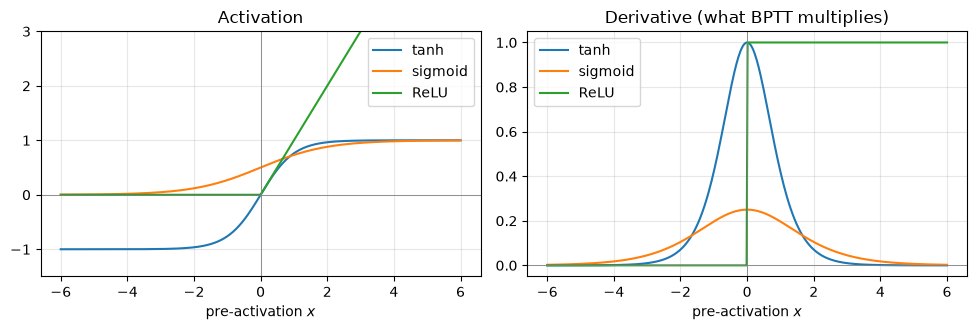

tanh'(0) = 1 - tanh^2 = 1.00000
tanh'(1) = 1 - tanh^2 = 0.41997
tanh'(2) = 1 - tanh^2 = 0.07065
tanh'(5) = 1 - tanh^2 = 0.00018

a factor of 0.8 per step over 100 steps: 0.8**100 = 2.0e-10  (illustrative; real BPTT multiplies matrices)


In [6]:
z = torch.linspace(-6, 6, 400, requires_grad=True)
acts = {"tanh": torch.tanh, "sigmoid": torch.sigmoid, "ReLU": torch.relu}

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for name, f in acts.items():
    y = f(z)
    (g,) = torch.autograd.grad(y.sum(), z)
    axes[0].plot(z.detach(), y.detach(), label=name)
    axes[1].plot(z.detach(), g, label=name)
axes[0].set_title("Activation"); axes[1].set_title("Derivative (what BPTT multiplies)")
for ax in axes:
    ax.axhline(0, color="gray", lw=0.6); ax.axvline(0, color="gray", lw=0.6)
    ax.grid(alpha=.3); ax.legend(); ax.set_xlabel("pre-activation $x$")
axes[0].set_ylim(-1.5, 3)
plt.tight_layout(); plt.show()

for v in [0.0, 1.0, 2.0, 5.0]:
    print(f"tanh'({v:.0f}) = 1 - tanh^2 = {1 - math.tanh(v) ** 2:.5f}")
print(f"\na factor of 0.8 per step over 100 steps: 0.8**100 = {0.8 ** 100:.1e}  (illustrative; real BPTT multiplies matrices)")

**Read the plot:** tanh's slope is largest (1) at the origin and collapses in both tails; sigmoid's slope never exceeds 0.25, so it shrinks gradients even faster; ReLU's slope is exactly 1 for positive inputs (no saturation) but its output is unbounded.

**In 30 seconds (interview answer):** *Vanilla RNNs use tanh because it is nonlinear, zero-centered and bounded in $(-1,1)$, which keeps the recurrent hidden state in a stable range. But tanh saturates for large inputs, and its small derivatives, multiplied across time steps in BPTT, contribute to vanishing gradients. ReLU avoids saturation on the positive side but produces unbounded activations, which makes the recurrent dynamics harder to stabilize.*

<details><summary><b>Quick check:</b> a tanh unit's pre-activation is 3. Roughly what fraction of the incoming gradient passes through it? (a) 100% (b) 50% (c) about 1% (d) exactly 0</summary>

**(c)** $\tanh'(3)=1-\tanh^2(3)\approx 0.0099$, about 1%. The unit is saturated; through many such steps the gradient vanishes.
</details>

## 3. The challenge of learning long-range interactions

📘 *[MLPyTorch Ch15] figure*

Training an RNN uses **backpropagation through time** (BPTT). The gradient of a loss at step $T$ with respect to an early hidden state is a product of one Jacobian per step:

$$
\frac{\partial h^{(T)}}{\partial h^{(1)}}=\prod_{t=2}^{T}\frac{\partial h^{(t)}}{\partial h^{(t-1)}}
=\prod_{t=2}^{T}\operatorname{diag}\!\big(1-(h^{(t)})^2\big)\,W_{hh}.
$$

<img src="https://github.com/chungenyu6/ai-learning-notebooks/blob/main/02-LLM/live/00-rnn_lstm_to_transformer/img/15_08.png?raw=true" width="500px">

*Figure: with a recurrent weight below 1 the signal vanishes, above 1 it explodes; only $|w_{hh}|=1$ preserves it. Source: MLPyTorch Ch15, Fig. 15.8.*

The one-dimensional picture generalizes: if the typical singular value of each factor is below 1 the product shrinks **exponentially** in $T$. Gradient clipping fixes explosion, **not** vanishing. Common remedies: gradient clipping, truncated BPTT, and — most effectively — gated cells such as the LSTM.

Let us measure $\lVert\partial h^{(T)}/\partial x^{(1)}\rVert$ for a freshly initialized RNN and LSTM:

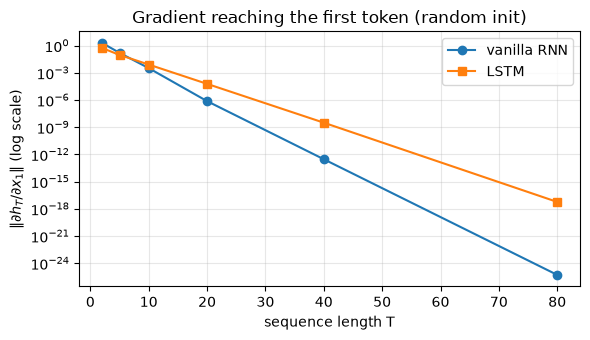

T=  2   RNN 1.93e+00   LSTM 5.34e-01
T=  5   RNN 1.55e-01   LSTM 9.16e-02
T= 10   RNN 3.20e-03   LSTM 7.95e-03
T= 20   RNN 7.32e-07   LSTM 5.90e-05
T= 40   RNN 2.87e-13   LSTM 3.08e-09
T= 80   RNN 5.01e-26   LSTM 5.59e-18


In [7]:
def grad_from_first_input(cell_kind, T, d=64, seed=0):
    torch.manual_seed(seed)
    x = torch.randn(1, T, d, dtype=torch.float64, requires_grad=True)   # float64: avoid underflow
    net = (nn.RNN if cell_kind == "RNN" else nn.LSTM)(d, d, batch_first=True).double()
    out, _ = net(x)
    out[0, -1].sum().backward()
    return x.grad[0, 0].norm().item()

Ts = [2, 5, 10, 20, 40, 80]
g_rnn = [sum(grad_from_first_input("RNN", T, seed=s) for s in range(5)) / 5 for T in Ts]
g_lstm = [sum(grad_from_first_input("LSTM", T, seed=s) for s in range(5)) / 5 for T in Ts]

plt.figure(figsize=(6, 3.5))
plt.semilogy(Ts, g_rnn, "o-", label="vanilla RNN")
plt.semilogy(Ts, g_lstm, "s-", label="LSTM")
plt.xlabel("sequence length T"); plt.ylabel(r"$\|\partial h_T / \partial x_1\|$ (log scale)")
plt.title("Gradient reaching the first token (random init)")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()
for T, a, b in zip(Ts, g_rnn, g_lstm):
    print(f"T={T:3d}   RNN {a:.2e}   LSTM {b:.2e}")

A straight line on a log axis is the signature of **exponential decay**. A random, untrained LSTM also decays; its advantage is that training can *learn* to keep its forget gate near 1 and open an almost-identity path through time (see Part 7).

Two different failures are mixed up here, and gated cells address both:

1. **Overwriting (forward):** a vanilla RNN recomputes all of $h_t$ at every step; nothing lets it *decide* to keep an old piece of information, so early content is gradually overwritten. In *"I grew up in Taiwan … (100 words) … I speak fluent ___"*, "Taiwan" must survive 100 rewrites.
2. **Vanishing gradients (backward):** even if the information survives the forward pass, the gradient that would teach the network to keep it shrinks with every step on the way back.

<details><summary><b>Quick check:</b> you add gradient clipping to a vanilla RNN that cannot learn a 100-step dependency. Does that fix it?</summary>

**No.** Clipping caps *exploding* gradients by rescaling their norm. A gradient that is already tiny is left unchanged, so the long-range signal is still lost. Remedies are architectural (gating, residual paths, attention) or partial (better initialization, truncated BPTT for cost).
</details>

## 4. Long short-term memory (LSTM)

📘 *[MLPyTorch Ch15] figure*

<img src="https://github.com/chungenyu6/ai-learning-notebooks/blob/main/02-LLM/live/00-rnn_lstm_to_transformer/img/15_09.png?raw=true" width="650px">

*Figure: the LSTM cell — forget gate $f$, input gate $i$, candidate $\tilde{C}$, output gate $o$, and the cell state $C$ running along the top. Source: MLPyTorch Ch15, Fig. 15.9.*

$$
\begin{aligned}
f_t &= \sigma(W_{xf}x_t+W_{hf}h_{t-1}+b_f) &&\text{how much old memory to keep}\\
i_t &= \sigma(W_{xi}x_t+W_{hi}h_{t-1}+b_i) &&\text{how much new content to write}\\
\tilde C_t &= \tanh(W_{xc}x_t+W_{hc}h_{t-1}+b_c) &&\text{candidate content}\\
o_t &= \sigma(W_{xo}x_t+W_{ho}h_{t-1}+b_o) &&\text{how much memory to expose}\\
C_t &= f_t\odot C_{t-1} + i_t\odot \tilde C_t, \qquad h_t = o_t\odot\tanh(C_t)
\end{aligned}
$$

The key is the **additive** cell-state update. Along that path $\partial C_t/\partial C_{t-1}\approx\operatorname{diag}(f_t)$: with $f_t\approx1$ the gradient passes almost unchanged — the same idea as the **residual connection** in every Transformer block.

A from-scratch cell, checked against PyTorch:

In [8]:
class LSTMCellScratch(nn.Module):
    def __init__(self, d_in, d_h):
        super().__init__()
        self.x2g = nn.Linear(d_in, 4 * d_h)              # all four gates in one matmul
        self.h2g = nn.Linear(d_h, 4 * d_h)

    def forward(self, x, state):
        h, c = state
        i, f, g, o = (self.x2g(x) + self.h2g(h)).chunk(4, dim=-1)   # PyTorch gate order: i, f, g, o
        i, f, g, o = torch.sigmoid(i), torch.sigmoid(f), torch.tanh(g), torch.sigmoid(o)
        c = f * c + i * g
        h = o * torch.tanh(c)
        return h, c

d_in, d_h = 8, 16
ref = nn.LSTMCell(d_in, d_h)
mine = LSTMCellScratch(d_in, d_h)
with torch.no_grad():
    mine.x2g.weight.copy_(ref.weight_ih); mine.x2g.bias.copy_(ref.bias_ih)
    mine.h2g.weight.copy_(ref.weight_hh); mine.h2g.bias.copy_(ref.bias_hh)
x = torch.randn(4, d_in); h0 = torch.randn(4, d_h); c0 = torch.randn(4, d_h)
h_ref, c_ref = ref(x, (h0, c0))
h_me, c_me = mine(x, (h0, c0))
assert torch.allclose(h_ref, h_me, atol=1e-6) and torch.allclose(c_ref, c_me, atol=1e-6)
print("scratch LSTM cell matches nn.LSTMCell ✓")

scratch LSTM cell matches nn.LSTMCell ✓


**Why sigmoid *and* tanh inside an LSTM?** The roles are different: **sigmoid controls how much** (a gate value between 0 and 1 for forgetting, writing or exposing), **tanh represents what** (signed, bounded candidate content). Note that the cell state $C_t$ itself is **not** bounded — it is a running sum — which is exactly what lets it carry information unchanged.

Feynman version: a vanilla RNN rewrites the whole page of notes every time it hears a word; an LSTM keeps a notebook and only edits the lines that need changing. Set $f_t\approx1$ and $i_t\approx0$ and the cell state is simply copied forward: $C_t\approx C_{t-1}$.

The LSTM does **not** fully solve vanishing gradients: it provides a path along which gradients flow well when the forget gate stays open, but the gates, the other paths and very long sequences still matter.

<details><summary><b>Quick check:</b> in an LSTM the forget gate is close to 1 and the input gate close to 0. What happens to the cell state? (a) it is cleared (b) it stays roughly the same (c) it becomes 0 at every step (d) it becomes the hidden state</summary>

**(b)** $C_t=f_t\odot C_{t-1}+i_t\odot\tilde C_t\approx C_{t-1}$: the memory is kept, and along this path $\partial C_t/\partial C_{t-1}\approx f_t\approx 1$, so gradients pass through too.
</details>

### GRU: do we need three gates?

The **gated recurrent unit** (Cho et al., 2014) keeps the main idea with less machinery: no separate cell state, two gates.

$$
\begin{aligned}
z_t &= \sigma(W_zx_t+U_zh_{t-1}+b_z) &&\text{update gate: how much old state to keep}\\
r_t &= \sigma(W_rx_t+U_rh_{t-1}+b_r) &&\text{reset gate: how much old state to use for the candidate}\\
\tilde h_t &= \tanh\!\big(W_hx_t+r_t\odot(U_hh_{t-1})+b_h\big) &&\text{candidate state}\\
h_t &= z_t\odot h_{t-1}+(1-z_t)\odot\tilde h_t
\end{aligned}
$$

The last line mirrors the LSTM cell update $C_t=f_t\odot C_{t-1}+i_t\odot\tilde C_t$, except that **one** gate sets both proportions ($z_t$ and $1-z_t$), coupling "forget" and "write". Conventions vary: some texts swap $z_t$ and $1-z_t$, and the original paper applies the reset gate *before* the matrix ($U_h(r_t\odot h_{t-1})$) while PyTorch/cuDNN apply it after, as written above. A from-scratch cell checked against `nn.GRUCell`:

In [9]:
class GRUCellScratch(nn.Module):
    def __init__(self, d_in, d_h):
        super().__init__()
        self.x2g = nn.Linear(d_in, 3 * d_h)              # PyTorch gate order: r, z, n
        self.h2g = nn.Linear(d_h, 3 * d_h)

    def forward(self, x, h):
        xr, xz, xn = self.x2g(x).chunk(3, dim=-1)
        hr, hz, hn = self.h2g(h).chunk(3, dim=-1)
        r = torch.sigmoid(xr + hr)
        z = torch.sigmoid(xz + hz)
        n = torch.tanh(xn + r * hn)                      # reset gate applied after the hidden projection
        return z * h + (1 - z) * n

ref = nn.GRUCell(d_in, d_h)
mine = GRUCellScratch(d_in, d_h)
with torch.no_grad():
    mine.x2g.weight.copy_(ref.weight_ih); mine.x2g.bias.copy_(ref.bias_ih)
    mine.h2g.weight.copy_(ref.weight_hh); mine.h2g.bias.copy_(ref.bias_hh)
assert torch.allclose(ref(x, h0), mine(x, h0), atol=1e-6)
print("scratch GRU cell matches nn.GRUCell ✓")

# same input and hidden size -> parameter counts in the ratio 1 : 4 : 3
for name, cls in [("RNN", nn.RNN), ("LSTM", nn.LSTM), ("GRU", nn.GRU)]:
    n = sum(p.numel() for p in cls(input_size=256, hidden_size=256).parameters())
    print(f"{name:4s} (256 -> 256): {n:7,} parameters")

scratch GRU cell matches nn.GRUCell ✓
RNN  (256 -> 256): 131,584 parameters
LSTM (256 -> 256): 526,336 parameters
GRU  (256 -> 256): 394,752 parameters


Each gate is one more pair of weight matrices: the LSTM has 4 blocks (i, f, g, o), the GRU 3 (r, z, n), the vanilla RNN 1.

| | Vanilla RNN | LSTM | GRU |
|---|---|---|---|
| Hidden state $h_t$ | yes | yes | yes |
| Separate cell state $c_t$ | no | **yes** | no |
| Gates | 0 | 3 (forget, input, output) | 2 (update, reset) |
| Activations | tanh | sigmoid (gates) + tanh (content) | sigmoid + tanh |
| Parameters (same sizes) | 1× | 4× | 3× |
| Long-range dependencies | hard | better | better |
| What helps the gradient | nothing dedicated | additive cell-state path | gated interpolation of $h_t$ |
| Guarantees long-term memory? | no | no | no |

**Three common misconceptions**

- *"LSTM solves vanishing gradients."* It eases them; long sequences can still be hard.
- *"GRU has no cell state, so it cannot keep long-term memory."* It keeps memory in $h_t$ itself, protected by the update gate.
- *"LSTM is more complex, so it is always better."* Neither wins everywhere; GRU has fewer parameters, sometimes trains more easily, and often matches the LSTM.

**Two independent choices.** RNN, LSTM and GRU are *cell types*; single- vs multi-layer is *depth*. A "3-layer LSTM" has three stacked LSTM cells at every time step, each with its own $h_t^{(l)}$ and $c_t^{(l)}$ — not three time steps.

<details><summary><b>Quick check 1:</b> an LSTM with sequence length 100 and 3 layers, unrolled in time — how many LSTM-cell evaluations? (a) 100 (b) 300 (c) 3 (d) 900</summary>

**(b) 300** — 100 time steps × 3 layers.
</details>

<details><summary><b>Quick check 2:</b> why does the GRU not need a separate cell state? (a) it needs no memory (b) it uses attention (c) its gated update of the hidden state does the job (d) it has no recurrent connection</summary>

**(c)** $h_t=z_t\odot h_{t-1}+(1-z_t)\odot\tilde h_t$ can copy the old state forward when $z_t\approx1$, the same additive "keep" path the LSTM gets from its cell state.
</details>

## 5. Project: a character-level LSTM language model

📘 *[MLPyTorch Ch15] figures and code (adapted for CPU/Colab)*

This is the same objective a GPT uses — **predict the next token** — with characters as tokens and an LSTM as the model.

<img src="https://github.com/chungenyu6/ai-learning-notebooks/blob/main/02-LLM/live/00-rnn_lstm_to_transformer/img/15_11.png?raw=true" width="600px">

*Figure: break text into characters; at every position the target is the next character. Source: MLPyTorch Ch15, Fig. 15.11.*

The training text is Jules Verne's *The Mysterious Island* (Project Gutenberg, public domain).

In [10]:
# download helper: local copy -> this repo -> original book repo
fname = "1268-0.txt"
urls = [
    "https://raw.githubusercontent.com/chungenyu6/ai-learning-notebooks/main/02-LLM/live/00-rnn_lstm_to_transformer/data/1268-0.txt",
    "https://raw.githubusercontent.com/rasbt/machine-learning-book/main/ch15/1268-0.txt",
]
local = os.path.join("00-rnn_lstm_to_transformer", "data", fname)
if os.path.exists(local):
    fname = local
elif not os.path.exists(fname):
    for url in urls:
        try:
            urllib.request.urlretrieve(url, fname); break
        except Exception as e:
            print("could not download", url, e)
print("using", fname)

using 00-rnn_lstm_to_transformer/data/1268-0.txt


In [11]:
# Source: MLPyTorch Ch15, ch15_part3.ipynb
## Reading and processing text
with open(fname, 'r', encoding="utf8") as fp:
    text=fp.read()

start_indx = text.find('THE MYSTERIOUS ISLAND')
end_indx = text.find('End of the Project Gutenberg')

text = text[start_indx:end_indx]
char_set = set(text)
print('Total Length:', len(text))
print('Unique Characters:', len(char_set))

Total Length: 1112350
Unique Characters: 80


Each character is mapped to an integer id — the simplest possible **tokenizer** (`01_tokenization_clm_mlm` replaces it with subword BPE):

<img src="https://github.com/chungenyu6/ai-learning-notebooks/blob/main/02-LLM/live/00-rnn_lstm_to_transformer/img/15_12.png?raw=true" width="500px">

*Figure: dictionaries mapping characters to integers and back. Source: MLPyTorch Ch15, Fig. 15.12.*

In [12]:
# Source: MLPyTorch Ch15, ch15_part3.ipynb
chars_sorted = sorted(char_set)
char2int = {ch:i for i,ch in enumerate(chars_sorted)}
char_array = np.array(chars_sorted)

text_encoded = np.array(
    [char2int[ch] for ch in text],
    dtype=np.int32)

print('Text encoded shape: ', text_encoded.shape)

print(text[:15], '     == Encoding ==> ', text_encoded[:15])
print(text_encoded[15:21], ' == Reverse  ==> ', ''.join(char_array[text_encoded[15:21]]))

Text encoded shape:  (1112350,)
THE MYSTERIOUS       == Encoding ==>  [44 32 29  1 37 48 43 44 29 42 33 39 45 43  1]
[33 43 36 25 38 28]  == Reverse  ==>  ISLAND


Training examples are fixed-length chunks. The book contrasts two ways to build targets — predicting only the character *after* the chunk (left), or the **input shifted by one** at every position (right). The shifted version gives a training signal at every step and is exactly how GPT-style models are trained:

<img src="https://github.com/chungenyu6/ai-learning-notebooks/blob/main/02-LLM/live/00-rnn_lstm_to_transformer/img/15_13.png?raw=true" width="420px"> <img src="https://github.com/chungenyu6/ai-learning-notebooks/blob/main/02-LLM/live/00-rnn_lstm_to_transformer/img/15_14.png?raw=true" width="420px">

*Figures: one target per chunk vs. input/target shifted by one. Source: MLPyTorch Ch15, Figs. 15.13–15.14.*

In [13]:
# Source: MLPyTorch Ch15, ch15_part3.ipynb
seq_length = 40
chunk_size = seq_length + 1

text_chunks = [text_encoded[i:i+chunk_size]
               for i in range(len(text_encoded)-chunk_size+1)]

from torch.utils.data import Dataset

class TextDataset(Dataset):
    def __init__(self, text_chunks):
        self.text_chunks = text_chunks

    def __len__(self):
        return len(self.text_chunks)

    def __getitem__(self, idx):
        text_chunk = self.text_chunks[idx]
        return text_chunk[:-1].long(), text_chunk[1:].long()

seq_dataset = TextDataset(torch.tensor(np.array(text_chunks)))

for i, (seq, target) in enumerate(seq_dataset):
    print(' Input (x):', repr(''.join(char_array[seq])))
    print('Target (y):', repr(''.join(char_array[target])))
    print()
    if i == 1:
        break

 Input (x): 'THE MYSTERIOUS ISLAND ***\n\n\n\n\nProduced b'
Target (y): 'HE MYSTERIOUS ISLAND ***\n\n\n\n\nProduced by'

 Input (x): 'HE MYSTERIOUS ISLAND ***\n\n\n\n\nProduced by'
Target (y): 'E MYSTERIOUS ISLAND ***\n\n\n\n\nProduced by '



In [14]:
# Source: MLPyTorch Ch15, ch15_part3.ipynb
from torch.utils.data import DataLoader

batch_size = 64

torch.manual_seed(1)
seq_dl = DataLoader(seq_dataset, batch_size=batch_size, shuffle=True, drop_last=True)

class RNN(nn.Module):
    def __init__(self, vocab_size, embed_dim, rnn_hidden_size):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim)
        self.rnn_hidden_size = rnn_hidden_size
        self.rnn = nn.LSTM(embed_dim, rnn_hidden_size,
                           batch_first=True)
        self.fc = nn.Linear(rnn_hidden_size, vocab_size)

    def forward(self, x, hidden, cell):
        out = self.embedding(x).unsqueeze(1)
        out, (hidden, cell) = self.rnn(out, (hidden, cell))
        out = self.fc(out).reshape(out.size(0), -1)
        return out, hidden, cell

    def init_hidden(self, batch_size):
        hidden = torch.zeros(1, batch_size, self.rnn_hidden_size)
        cell = torch.zeros(1, batch_size, self.rnn_hidden_size)
        return hidden.to(device), cell.to(device)

vocab_size = len(char_array)
embed_dim = 256
rnn_hidden_size = 512

torch.manual_seed(1)
model = RNN(vocab_size, embed_dim, rnn_hidden_size)
model = model.to(device)
model

RNN(
  (embedding): Embedding(80, 256)
  (rnn): LSTM(256, 512, batch_first=True)
  (fc): Linear(in_features=512, out_features=80, bias=True)
)

The training loop feeds **one character per step** and carries `(hidden, cell)` forward — the sequential bottleneck in action. The book trains for 10,000 iterations on a GPU; on a CPU runtime we use 800 (≈2–4 minutes), which is enough to learn words and punctuation. Switch Colab to a GPU runtime to run the full schedule.

In [15]:
# Source: MLPyTorch Ch15, ch15_part3.ipynb; iteration count adapted for CPU
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.005)

num_epochs = 10000 if device.type == "cuda" else 800
print_every = 500 if device.type == "cuda" else 100

torch.manual_seed(1)
t0 = time.time()
for epoch in range(num_epochs):
    hidden, cell = model.init_hidden(batch_size)
    seq_batch, target_batch = next(iter(seq_dl))
    seq_batch = seq_batch.to(device)
    target_batch = target_batch.to(device)
    optimizer.zero_grad()
    loss = 0
    for c in range(seq_length):
        pred, hidden, cell = model(seq_batch[:, c], hidden, cell)
        loss += loss_fn(pred, target_batch[:, c])
    loss.backward()
    optimizer.step()
    loss = loss.item()/seq_length
    if epoch % print_every == 0 or epoch == num_epochs - 1:
        print(f'Epoch {epoch} loss: {loss:.4f}')
print(f"({time.time() - t0:.0f}s)")

Epoch 0 loss: 4.3722


Epoch 100 loss: 1.7092


Epoch 200 loss: 1.5436


Epoch 300 loss: 1.4602


Epoch 400 loss: 1.4387


Epoch 500 loss: 1.3920


Epoch 600 loss: 1.3356


Epoch 700 loss: 1.3491


Epoch 799 loss: 1.3046
(74s)


### Generating text, and the temperature knob

Generation is autoregressive: sample a character from the predicted distribution, feed it back, repeat. The book scales the logits by a factor $\alpha$ before sampling — $\alpha>1$ sharpens the distribution (more predictable), $\alpha<1$ flattens it (more random). This is the same knob LLM APIs expose as **temperature** $T = 1/\alpha$.

In [16]:
# Source: MLPyTorch Ch15, ch15_part3.ipynb
from torch.distributions.categorical import Categorical

logits = torch.tensor([[1.0, 1.0, 3.0]])

print('Probabilities before scaling:        ', nn.functional.softmax(logits, dim=1).numpy()[0])

print('Probabilities after scaling with 0.5:', nn.functional.softmax(0.5*logits, dim=1).numpy()[0])

print('Probabilities after scaling with 0.1:', nn.functional.softmax(0.1*logits, dim=1).numpy()[0])

Probabilities before scaling:         [0.10650698 0.10650698 0.78698605]
Probabilities after scaling with 0.5: [0.21194156 0.21194156 0.57611686]
Probabilities after scaling with 0.1: [0.3104238  0.3104238  0.37915248]


In [17]:
# Source: MLPyTorch Ch15, ch15_part3.ipynb; device handling adapted
def sample(model, starting_str,
           len_generated_text=500,
           scale_factor=1.0):

    encoded_input = torch.tensor([char2int[s] for s in starting_str])
    encoded_input = torch.reshape(encoded_input, (1, -1))

    generated_str = starting_str

    model.eval()
    hidden, cell = model.init_hidden(1)
    hidden = hidden.to('cpu')
    cell = cell.to('cpu')
    for c in range(len(starting_str)-1):
        _, hidden, cell = model(encoded_input[:, c].view(1), hidden, cell)

    last_char = encoded_input[:, -1]
    for i in range(len_generated_text):
        logits, hidden, cell = model(last_char.view(1), hidden, cell)
        logits = torch.squeeze(logits, 0)
        scaled_logits = logits * scale_factor
        m = Categorical(logits=scaled_logits)
        last_char = m.sample()
        generated_str += str(char_array[last_char])

    return generated_str

model.to('cpu')
device = torch.device('cpu')   # sampling runs on CPU, as in the book
for scale in (2.0, 1.0, 0.5):
    torch.manual_seed(1)
    print(f"--- scale_factor={scale} ---")
    print(sample(model, starting_str='The island', len_generated_text=250, scale_factor=scale))
    print()

--- scale_factor=2.0 ---
The island would be the reporter was the sea, and the wood of the corral, and the sailor, “you under the strange for the sailor, “that it was nothing of the distance of the colonists was evident the wire the moment as if there was the mouth of the carry of the

--- scale_factor=1.0 ---
The island would dimight enormous to be from the reporter, “and, for which the halso howh, was undoed an hour at fifty miles, whont nor their still be only extremity of the Chimneys, was evidencict-masion
touce to the island.

“They were
there was carry build 

--- scale_factor=0.5 ---
The island foxmess, 16 jTe
me alwDested from?

Neverblank, engs,)-cafward. LI. QKpSLI7” hareable
doera, my debainffel.
LixIshWvede.

“My trave quarting’sly.”

Tbodsyd*cadlud, Cyruate Wasoen, Picirtyins
intle, elkilors instrucfet lying!0Ze1se, Nemo caOyals.

Bu



**What to notice.** Even this small LSTM learns spelling, spacing and punctuation. It loses the thread across sentences: everything the model knows about the past must squeeze through the fixed-size `(hidden, cell)` vectors, one step at a time.

## 6. From RNNs to attention to the Transformer

📗 *[LLMs-from-scratch Ch3] text (§3.1–3.2) and figures*

**The problem with modeling long sequences.** Translating word by word does not work because grammatical structure differs between languages:

<img src="https://github.com/chungenyu6/ai-learning-notebooks/blob/main/02-LLM/live/00-rnn_lstm_to_transformer/img/ch03_03.webp?raw=true" width="400px">

*Figure: word-by-word translation fails. Source: Raschka, LLMs-from-scratch Ch3 (original image `ch03_compressed/03.webp`).*

Before Transformers, **encoder–decoder RNNs** were the standard for translation: the encoder reads the source sentence and compresses it into a hidden state; the decoder generates the translation from that state.

<img src="https://github.com/chungenyu6/ai-learning-notebooks/blob/main/02-LLM/live/00-rnn_lstm_to_transformer/img/ch03_04.webp?raw=true" width="500px">

*Figure: encoder–decoder RNN; the whole input must pass through the final hidden state. Source: Raschka, LLMs-from-scratch Ch3 (original image `ch03_compressed/04.webp`).*

Two problems follow: a **bottleneck** (one fixed vector for an arbitrarily long sentence) and **distance** (word 1 must survive every recurrent step).

**Capturing data dependencies with attention.** With an attention mechanism (Bahdanau et al., 2015) the decoder can selectively access *all* encoder states, weighting some input tokens more than others for each output token:

<img src="https://github.com/chungenyu6/ai-learning-notebooks/blob/main/02-LLM/live/00-rnn_lstm_to_transformer/img/ch03_05.webp?raw=true" width="500px">

*Figure: attention lets the decoder look at all input tokens. Source: Raschka, LLMs-from-scratch Ch3 (original image `ch03_compressed/05.webp`).*

**Self-attention** in Transformers (Vaswani et al., 2017) lets each position in a sequence attend to every other (allowed) position *in the same sequence* — no recurrence at all:

<img src="https://github.com/chungenyu6/ai-learning-notebooks/blob/main/02-LLM/live/00-rnn_lstm_to_transformer/img/ch03_06.webp?raw=true" width="300px">

*Figure: self-attention within one sequence. Source: Raschka, LLMs-from-scratch Ch3 (original image `ch03_compressed/06.webp`).*

$$
\operatorname{Attention}(Q,K,V)=\operatorname{softmax}\!\Big(\frac{QK^\top}{\sqrt{d_k}} + M\Big)V,
$$

where $Q,K,V$ are projections of the same sequence and $M$ is the causal mask ($-\infty$ above the diagonal). The main notebook `02_attention.ipynb` and `02_self_and_cross_attention` derive every symbol; here is just the consequence:

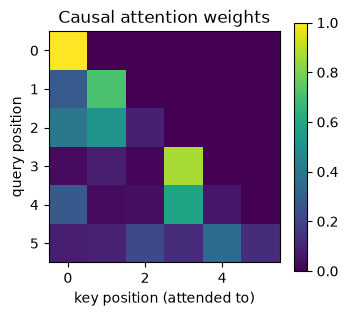

rows sum to 1: True


In [18]:
def causal_self_attention(x, Wq, Wk, Wv):
    """Single-head causal self-attention. x: (B, T, d)."""
    q, k, v = x @ Wq, x @ Wk, x @ Wv
    T = x.shape[1]
    scores = q @ k.transpose(-2, -1) / math.sqrt(q.shape[-1])     # (B, T, T): every pair at once
    mask = torch.triu(torch.ones(T, T, dtype=torch.bool), diagonal=1)
    scores = scores.masked_fill(mask, float("-inf"))
    weights = F.softmax(scores, dim=-1)
    return weights @ v, weights

torch.manual_seed(0)
d = 16
x = torch.randn(1, 6, d)
Wq, Wk, Wv = (torch.randn(d, d) / math.sqrt(d) for _ in range(3))
_, w = causal_self_attention(x, Wq, Wk, Wv)
plt.figure(figsize=(3.6, 3.2))
plt.imshow(w[0].detach(), cmap="viridis"); plt.colorbar()
plt.xlabel("key position (attended to)"); plt.ylabel("query position")
plt.title("Causal attention weights"); plt.tight_layout(); plt.show()
print("rows sum to 1:", torch.allclose(w.sum(-1), torch.ones(1, 6)))

Row $t$ shows how token $t$ mixes information from tokens $1..t$; the upper triangle is exactly zero. There is **no loop over time**: token 6 reaches token 1 in one step.

| | RNN / LSTM | Self-attention |
|---|---|---|
| Sequential steps to process $T$ tokens (training) | $O(T)$ — cannot parallelize over time | $O(1)$ — one big matrix multiply |
| Path length between tokens $i$ and $j$ | $O(\lvert i-j\rvert)$ | $O(1)$ |
| Compute per layer | $O(T d^2)$ | $O(T^2 d + T d^2)$ |
| Memory of the past during generation | fixed-size $h_t$ (cheap, lossy) | all past keys/values (exact, grows with $T$ → **KV cache**, see `03_gqa_kv_cache`) |
| Knows word order by itself? | yes (order of the loop) | **no** — needs positional information (learned / sinusoidal / RoPE) |

**Why gating was not the end of the story.** Consider a 1,000-token document whose last token depends on the first. Even an LSTM has two structural limits:

- **Sequential computation.** $h_{1000}=f(x_{1000},h_{999})$ needs $h_{999}$, which needs $h_{998}$, … — the time steps cannot be computed in parallel, even during training when the whole text is known.
- **A fixed-size bottleneck.** Everything about the past must be squeezed into a hidden (and cell) state of fixed width; the model must constantly choose what to keep.

Self-attention removes both: each token looks up any earlier token directly (as a weighted mix chosen by query–key similarity), and all positions are computed at once.

| | Vanilla RNN | LSTM / GRU | Transformer |
|---|---|---|---|
| Core mechanism | recurrent hidden state | gated recurrence | self-attention |
| Computation over time (training) | sequential | sequential | parallel across positions |
| Long-range dependencies | hard | better | direct interaction at any distance |
| Memory of the past | hidden state | gated states | all token representations (KV cache at inference) |
| Path between distant tokens | grows with distance | grows with distance | one attention step per layer |
| Standard attention matrix | — | — | $O(n^2)$ in sequence length |
| Word order | built into the recurrence | built into the recurrence | must be added (positions, RoPE) |
| Autoregressive generation | one token at a time | one token at a time | **still one token at a time** |

The last row is the classic trap: Transformers parallelize over the tokens that are already known (training, or processing a prompt), but a GPT still **generates** one token after another; only the work inside each step is parallel.

<details><summary><b>Quick check 1:</b> why can a Transformer be parallelized over the sequence during training more easily than an RNN? (a) it uses tanh (b) self-attention does not need the previous time step's hidden state (c) it needs no gradients (d) it ignores word order</summary>

**(b)** Every position's output is a function of the (known) input tokens, not of a state produced by the previous step, so all positions are computed in one batched matrix multiply.
</details>

<details><summary><b>Quick check 2:</b> sequence length grows from 100 to 1,000. How many times larger is a standard dense attention matrix? (a) 10× (b) 100× (c) 1,000× (d) unchanged</summary>

**(b) 100×** — it has $n\times n$ entries: $10^4\to10^6$.
</details>

<details><summary><b>Quick check 3:</b> why does a Transformer need positional information? (a) softmax fails without it (b) all heads would have equal weights (c) self-attention has no built-in notion of position (d) Q, K, V must be scalars</summary>

**(c)** Without positions, self-attention is permutation-equivariant: shuffling the tokens only shuffles the outputs.
</details>

## 7. Experiment: who can remember the first token?

**Task.** Each sequence is `[k, n, n, ..., n]`: a *key* token followed by $L$ random *noise* tokens. At the last position the model must output the key — a pure long-range dependency. Three small models train for 600 steps each; chance is $1/8$. Models are not parameter-matched: the RNN–LSTM gap and the effect of $L$ are the point, not a benchmark.

L=  5  RNN 100%  LSTM 100%  Transformer 100%


L= 20  RNN 11%  LSTM 100%  Transformer 100%


L= 50  RNN 12%  LSTM 38%  Transformer 100%


L=100  RNN 13%  LSTM 12%  Transformer 100%


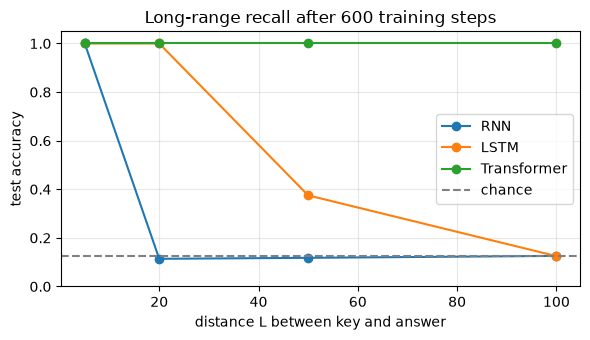

In [19]:
N_KEYS, N_NOISE = 8, 8
VOCAB = N_KEYS + N_NOISE

def recall_batch(L, B=64):
    keys = torch.randint(0, N_KEYS, (B,))
    noise = torch.randint(N_KEYS, VOCAB, (B, L))
    return torch.cat([keys[:, None], noise], dim=1), keys

class RecurrentClassifier(nn.Module):
    def __init__(self, kind, d=64):
        super().__init__()
        self.embed = nn.Embedding(VOCAB, d)
        self.rnn = (nn.RNN if kind == "RNN" else nn.LSTM)(d, d, batch_first=True)
        self.head = nn.Linear(d, N_KEYS)
        if kind == "LSTM":                                 # standard trick: forget-gate bias = 1,
            for name, p in self.rnn.named_parameters():   # so the cell starts by *remembering*
                if "bias" in name:
                    p.data[d:2 * d].fill_(1.0)             # gate order i, f, g, o -> slice 2 is f
    def forward(self, x):
        out, _ = self.rnn(self.embed(x))
        return self.head(out[:, -1])

class TinyTransformer(nn.Module):
    """One pre-norm Transformer block with learned positions and a causal mask."""
    def __init__(self, d=64, n_heads=4, max_len=256):
        super().__init__()
        self.embed = nn.Embedding(VOCAB, d)
        self.pos = nn.Embedding(max_len, d)
        layer = nn.TransformerEncoderLayer(d, n_heads, dim_feedforward=4 * d, dropout=0.0,
                                           batch_first=True, norm_first=True)
        self.block = nn.TransformerEncoder(layer, num_layers=1, enable_nested_tensor=False)
        self.head = nn.Linear(d, N_KEYS)
    def forward(self, x):
        T = x.shape[1]
        h = self.embed(x) + self.pos(torch.arange(T))
        mask = nn.Transformer.generate_square_subsequent_mask(T)
        return self.head(self.block(h, mask=mask, is_causal=True)[:, -1])

def train_and_eval(make_model, L, steps=600, seed=0):
    torch.manual_seed(seed)
    model = make_model()
    opt = torch.optim.Adam(model.parameters(), lr=3e-3)
    for _ in range(steps):
        x, y = recall_batch(L)
        loss = F.cross_entropy(model(x), y)
        opt.zero_grad(); loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
    with torch.no_grad():
        x, y = recall_batch(L, B=1000)
        return (model(x).argmax(-1) == y).float().mean().item()

models = {"RNN": lambda: RecurrentClassifier("RNN"),
          "LSTM": lambda: RecurrentClassifier("LSTM"),
          "Transformer": lambda: TinyTransformer()}
Ls = [5, 20, 50, 100]
results = {name: [] for name in models}
for L in Ls:
    for name, make in models.items():
        results[name].append(train_and_eval(make, L))
    print(f"L={L:3d}  " + "  ".join(f"{n} {results[n][-1]:.0%}" for n in models))

plt.figure(figsize=(6, 3.5))
for name, accs in results.items():
    plt.plot(Ls, accs, "o-", label=name)
plt.axhline(1 / N_KEYS, color="gray", ls="--", label="chance")
plt.xlabel("distance L between key and answer"); plt.ylabel("test accuracy")
plt.title("Long-range recall after 600 training steps")
plt.ylim(0, 1.05); plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

- The **vanilla RNN** solves short distances and collapses toward chance as $L$ grows.
- The **LSTM** holds on much longer thanks to the gated cell state, but it also degrades as $L$ grows — gating slows the decay, it does not remove it. (Without the forget-bias trick it fails at $L=20$ too: try setting the fill value to 0.)
- The **Transformer** reaches the key in one attention hop, so distance barely matters here. It pays with $O(T^2)$ attention and needs explicit position information.

## 8. Where this leads, and check yourself

```
token ids ─► embedding (+ position) ─► [ decoder block × N ] ─► logits ─► next-token loss
                                        │ masked self-attention │
                                        │ + MLP, residual, norm │
```

| Piece of the diagram | Main notebook | Extended material |
|---|---|---|
| token ids, embedding | `01_tokenization` | `01_tokenization_clm_mlm` |
| masked self-attention | `02_attention` | `02_self_and_cross_attention`, `03_gqa_kv_cache` |
| position information | `03_architecture_gpt` | `04_positional_encoding_rope` |
| decoder block × N | `03_architecture_gpt` | `05_gpt_vs_llama_vs_moe` |
| next-token loss, training loop | `04_pretraining` | `06_pretraining_pipeline` |
| fine-tuning | `05_finetuning_classification`, `06_finetuning_instructions` | `07_lora_peft` |

Try answering out loud in 60–90 seconds before opening each answer.

<details><summary><b>Q1. Why do vanilla RNNs struggle with long-range dependencies? Does gradient clipping fix it?</b></summary>

BPTT multiplies one Jacobian $\operatorname{diag}(1-h_t^2)W_{hh}$ per step, so the gradient from step $T$ to step 1 scales roughly like $\lVert W_{hh}\rVert^{T}$: it vanishes or explodes exponentially. Clipping caps exploding gradients but does nothing for vanishing ones. Fixes: gated cells (LSTM/GRU), careful init (orthogonal $W_{hh}$), truncated BPTT for cost, or attention, which gives a direct path.
</details>

<details><summary><b>Q2. What does each LSTM gate do, and why does the cell state help gradients?</b></summary>

Forget gate: how much of $C_{t-1}$ to keep; input gate: how much of the candidate to write; output gate: how much of $\tanh(C_t)$ to expose as $h_t$. Because $C_t=f_t\odot C_{t-1}+i_t\odot\tilde C_t$ is additive, $\partial C_t/\partial C_{t-1}\approx\operatorname{diag}(f_t)$; with $f_t\approx1$ the gradient flows almost unchanged — the same principle as residual connections. Initializing the forget-gate bias to 1 is a standard trick.
</details>

<details><summary><b>Q3. Why are Transformers faster to train than RNNs, but more expensive for long sequences?</b></summary>

With teacher forcing all positions are known, so self-attention computes every position in one batched matmul — no time loop, full GPU parallelism. The score matrix is $T\times T$, so compute and naive memory are $O(T^2)$ per layer versus $O(T)$ for an RNN. At generation time a Transformer keeps keys/values for all past tokens (the KV cache), while an RNN keeps a fixed-size state.
</details>

<details><summary><b>Q4. Self-attention is permutation-equivariant. What does that mean and how is it fixed?</b></summary>

Without position information, shuffling the input tokens just shuffles the outputs — attention sees a set, not a sequence. Fix: learned absolute embeddings (GPT-2), sinusoidal embeddings (original Transformer), or rotating Q and K by position (RoPE; Llama and most modern LLMs).
</details>

<details><summary><b>Q5. Training vs generation for a language model — what differs? What does temperature do?</b></summary>

Training: the input is the true sequence, targets are the same sequence shifted by one, loss averaged over all positions (teacher forcing). Generation: autoregressive — predict, sample, append, repeat; each step depends on previously *generated* tokens (exposure bias). Temperature divides the logits before softmax: low temperature → sharper, more deterministic; high → flatter, more diverse. The char-LSTM's `scale_factor` is 1/temperature.
</details>

<details><summary><b>Q6. Why do vanilla RNNs use tanh rather than ReLU or sigmoid?</b></summary>

tanh is nonlinear (without it the recurrence is linear), zero-centered (states can be positive or negative) and bounded in $(-1,1)$, which keeps a state that is fed back into itself from blowing up. Sigmoid is not zero-centered and its slope is at most 0.25. ReLU does not saturate on the positive side but is unbounded, which destabilizes recurrent dynamics. tanh's own weakness is saturation: $\tanh'(x)=1-\tanh^2(x)\to0$ for large $|x|$, contributing to vanishing gradients through time.
</details>

<details><summary><b>Q7. LSTM vs GRU — what is the difference, and which would you pick?</b></summary>

The LSTM has a separate cell state and three gates (forget, input, output); the GRU merges cell and hidden state and uses two gates, with one update gate coupling "forget" and "write". At equal sizes the GRU has about 3/4 of the LSTM's parameters and is a bit faster. Accuracy is task-dependent; neither dominates. Both ease but do not eliminate vanishing gradients, and both remain sequential over time.
</details>

## References

- Raschka, Liu & Mirjalili (2022), *Machine Learning with PyTorch and Scikit-Learn*, Ch. 15 — [rasbt/machine-learning-book](https://github.com/rasbt/machine-learning-book/tree/main/ch15).
- Raschka (2024), *Build a Large Language Model (From Scratch)*, Ch. 3 — [rasbt/LLMs-from-scratch](https://github.com/rasbt/LLMs-from-scratch/tree/main/ch03).
- Hochreiter & Schmidhuber (1997), *Long Short-Term Memory*.
- Bahdanau, Cho & Bengio (2015), *Neural Machine Translation by Jointly Learning to Align and Translate*, [arXiv:1409.0473](https://arxiv.org/abs/1409.0473).
- Vaswani et al. (2017), *Attention Is All You Need*, [arXiv:1706.03762](https://arxiv.org/abs/1706.03762).